# 05 - Feature Engineering and WoE / IV Analysis

**Project:** German Credit Risk
**Dataset:** `data/german_credit_data.csv`
**Author:** Divya Akbari

**Goal of this notebook**
1. Create new features from the raw data, based on what the statistical analysis showed.
2. Group (bin) every feature into a few clear bands.
3. Calculate the **Weight of Evidence (WoE)** for every band and the **Information Value (IV)** for every feature.
4. Select the features for modelling and save model-ready datasets.

**Key terms**
- **WoE** = ln(% of all good customers in the band / % of all bad customers in the band).
  A **positive** WoE means the band is **safer** than average; a **negative** WoE means it is **riskier**.
- **IV** adds up the WoE of all bands of a feature and measures how well the feature separates good and bad customers.
  Guide: below 0.02 = not useful, 0.02 to 0.1 = weak, 0.1 to 0.3 = medium, above 0.3 = strong.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

pd.set_option('display.width', 140)
pd.set_option('display.max_colwidth', None)

df = pd.read_csv('data/german_credit_data.csv')
df = df.drop(columns=['Unnamed: 0'])          # row number only
df['bad'] = (df['Risk'] == 'bad').astype(int)  # 1 = bad risk, 0 = good risk
print(df.shape)

(1000, 11)


## 1. Feature engineering

Each new feature comes from a finding in the earlier analysis:

| New feature | How it is made | Why |
|---|---|---|
| `checking_status` | Missing checking account becomes "no account" | Missing values have the lowest risk (11.7%), so they are a real group |
| `saving_status` | Missing becomes "no record"; "quite rich" and "rich" are joined | "rich" alone has only 4.8% of customers |
| `has_checking_account` | 1 if a checking account is recorded | Recorded accounts are much riskier (41.9% vs 11.7%) |
| `low_balance_profile` | 1 if checking is "little" and savings are "little" or not recorded | Combines the two strongest account signals |
| `monthly_payment` | Credit amount / Duration (DM per month) | Shows the size of the repayment, not just the loan |
| `log_credit_amount` | Natural log of credit amount | Reduces the strong right skew |
| `is_young` | 1 if age is 25 or under | Applicants aged 19 to 25 have a 42.1% bad rate |
| `long_loan` | 1 if duration is 24 months or more | Risk rises sharply for longer loans |
| `purpose_group` | Education, repairs, domestic appliances and vacation/others joined | These groups are small and have similar risk |
| `job_group` | Job 0 and 1 joined as "unskilled" | Job 0 has only 2.2% of customers |
| `owns_home` | 1 if housing is "own" | Owners are lower risk than renters and free housing |

In [2]:
fe = df.copy()

# Account features
fe['checking_status'] = fe['Checking account'].fillna('no account')
fe['saving_status'] = fe['Saving accounts'].fillna('no record').replace({'quite rich': 'quite rich/rich', 'rich': 'quite rich/rich'})
fe['has_checking_account'] = fe['Checking account'].notna().astype(int)
fe['low_balance_profile'] = ((fe['checking_status'] == 'little') &
                             (fe['saving_status'].isin(['little', 'no record']))).astype(int)

# Loan features
fe['monthly_payment'] = (fe['Credit amount'] / fe['Duration']).round(2)
fe['log_credit_amount'] = np.log(fe['Credit amount']).round(4)
fe['long_loan'] = (fe['Duration'] >= 24).astype(int)
fe['purpose_group'] = fe['Purpose'].replace({'education': 'education/other', 'repairs': 'education/other',
                                             'domestic appliances': 'education/other', 'vacation/others': 'education/other'})

# Applicant features
fe['is_young'] = (fe['Age'] <= 25).astype(int)
fe['job_group'] = fe['Job'].map({0: 'unskilled', 1: 'unskilled', 2: 'skilled', 3: 'highly skilled'})
fe['owns_home'] = (fe['Housing'] == 'own').astype(int)

new_features = ['checking_status', 'saving_status', 'has_checking_account', 'low_balance_profile', 'monthly_payment',
                'log_credit_amount', 'long_loan', 'purpose_group', 'is_young', 'job_group', 'owns_home']
fe[new_features].head()

,checking_status,saving_status,has_checking_account,low_balance_profile,monthly_payment,log_credit_amount,long_loan,purpose_group,is_young,job_group,owns_home
0,little,no record,1,1,194.83,7.0639,0,radio/TV,0,skilled,1
1,moderate,little,1,0,123.98,8.6913,1,radio/TV,1,skilled,1
2,no account,little,0,0,174.67,7.6478,0,education/other,0,unskilled,1
3,little,little,1,1,187.67,8.9723,1,furniture/equipment,0,skilled,0
4,little,little,1,1,202.92,8.4908,1,car,0,skilled,0


In [3]:
# Bad rate for the new yes/no features
flags = ['has_checking_account', 'low_balance_profile', 'long_loan', 'is_young', 'owns_home']
rows = []
for col in flags:
    for value in [1, 0]:
        group = fe[fe[col] == value]
        rows.append([col, 'yes' if value == 1 else 'no', len(group), round(group['bad'].mean() * 100, 1)])
pd.DataFrame(rows, columns=['Feature', 'Value', 'Customers', 'Bad rate (%)'])

,Feature,Value,Customers,Bad rate (%)
0,has_checking_account,yes,606,41.9
1,has_checking_account,no,394,11.7
2,low_balance_profile,yes,248,51.6
3,low_balance_profile,no,752,22.9
4,long_loan,yes,414,38.2
5,long_loan,no,586,24.2
6,is_young,yes,190,42.1
7,is_young,no,810,27.2
8,owns_home,yes,713,26.1
9,owns_home,no,287,39.7


In [4]:
fe[['monthly_payment', 'log_credit_amount']].describe().round(2)

,monthly_payment,log_credit_amount
count,1000.00,1000.00
mean,167.69,7.79
std,153.49,0.78
min,24.06,5.52
25%,89.60,7.22
50%,130.33,7.75
75%,206.18,8.29
max,2482.67,9.82


## 2. Binning (coarse classing)

WoE needs every feature split into bands. The rules used are:
- every band holds **at least 5%** of customers,
- every band has both good and bad customers,
- cut points are **round, easy-to-explain numbers**,
- the bad rate should move in a **logical direction** across the bands.

**Step 1 - fine classing:** split each numerical feature into 10 equal-sized groups to see the pattern.

In [5]:
def woe_table(data, feature):
    table = pd.crosstab(data[feature], data['bad'])
    good, bad = table[0], table[1]
    good_share = (good + 0.5) / good.sum()     # +0.5 avoids dividing by zero
    bad_share = (bad + 0.5) / bad.sum()
    woe = np.log(good_share / bad_share)
    return pd.DataFrame({
        'Customers': good + bad,
        'Share (%)': ((good + bad) / len(data) * 100).round(1),
        'Good': good,
        'Bad': bad,
        'Bad rate (%)': (bad / (good + bad) * 100).round(1),
        'WoE': woe.round(3),
        'IV part': ((good_share - bad_share) * woe).round(4),
    })

for col in ['Duration', 'Age', 'Credit amount', 'monthly_payment']:
    fine = fe[[col, 'bad']].copy()
    fine['decile'] = pd.qcut(fine[col], 10, duplicates='drop')
    print(col)
    print(woe_table(fine, 'decile')[['Customers', 'Bad rate (%)', 'WoE']])
    print()

Duration
              Customers  Bad rate (%)    WoE
decile                                      
(3.999, 9.0]        143          16.8  0.737
(9.0, 12.0]         216          24.1  0.295
(12.0, 15.0]         72          18.1  0.636
(15.0, 18.0]        115          37.4 -0.336
(18.0, 24.0]        224          29.5  0.021
(24.0, 30.0]         57          33.3 -0.167
(30.0, 36.0]         86          44.2 -0.616
(36.0, 72.0]         87          51.7 -0.916

Age
                Customers  Bad rate (%)    WoE
decile                                        
(18.999, 23.0]        105          40.0 -0.446
(23.0, 26.0]          135          38.5 -0.383
(26.0, 28.0]           94          29.8  0.000
(28.0, 30.0]           77          33.8 -0.183
(30.0, 33.0]          105          31.4 -0.075
(33.0, 36.0]          111          20.7  0.479
(36.0, 39.0]           74          24.3  0.269
(39.0, 45.0]          113          27.4  0.116
(45.0, 52.0]           90          20.0  0.519
(52.0, 75.0]       

**Step 2 - coarse classing:** neighbouring groups with similar risk are joined, using round cut points.
Several options were compared, and the one with the highest IV that still follows a logical pattern was chosen.

In [6]:
bins = {
    'Duration':        ([0, 11, 23, 35, 100],        ['up to 11', '12-23', '24-35', '36+']),
    'Age':             ([18, 25, 33, 100],           ['25 or under', '26-33', '34+']),
    'Credit amount':   ([0, 1500, 4000, 7500, 1e9],  ['up to 1,500', '1,501-4,000', '4,001-7,500', 'over 7,500']),
    'monthly_payment': ([0, 80, 150, 1e9],           ['up to 80', '81-150', 'over 150']),
}
bin_names = {'Duration': 'duration_bin', 'Age': 'age_bin', 'Credit amount': 'credit_bin', 'monthly_payment': 'payment_bin'}

for col, (edges, labels) in bins.items():
    fe[bin_names[col]] = pd.cut(fe[col], edges, labels=labels).astype(str)

fe[list(bin_names.values())].head()

,duration_bin,age_bin,credit_bin,payment_bin
0,up to 11,34+,"up to 1,500",over 150
1,36+,25 or under,"4,001-7,500",81-150
2,12-23,34+,"1,501-4,000",over 150
3,36+,34+,"over 7,500",over 150
4,24-35,34+,"4,001-7,500",over 150


## 3. WoE tables and Information Value

Ten candidate features are scored: the four binned numerical features and six categorical features.
`Sex` is scored for completeness, but it is a **protected characteristic** and will not be used for modelling.

In [7]:
candidates = {
    'checking_status': 'Checking account status',
    'low_balance_profile': 'Low balance profile',
    'duration_bin': 'Duration',
    'saving_status': 'Saving account status',
    'credit_bin': 'Credit amount',
    'age_bin': 'Age',
    'housing': 'Housing',
    'payment_bin': 'Monthly payment',
    'purpose_group': 'Purpose group',
    'sex': 'Sex',
    'job_group': 'Job group',
}
fe['housing'] = fe['Housing']
fe['sex'] = fe['Sex']

woe_tables = {f: woe_table(fe, f) for f in candidates}

for f, name in candidates.items():
    print('=' * 70)
    print(f'{name}  ({f})   IV = {woe_tables[f]["IV part"].sum():.3f}')
    print('=' * 70)
    print(woe_tables[f])
    print()

Checking account status  (checking_status)   IV = 0.662
                 Customers  Share (%)  Good  Bad  Bad rate (%)    WoE  IV part
checking_status                                                               
little                 274       27.4   139  135          49.3 -0.818   0.2065
moderate               269       26.9   164  105          39.0 -0.403   0.0470
no account             394       39.4   348   46          11.7  1.167   0.4001
rich                    63        6.3    49   14          22.2  0.381   0.0085

Low balance profile  (low_balance_profile)   IV = 0.327
                     Customers  Share (%)  Good  Bad  Bad rate (%)    WoE  IV part
low_balance_profile                                                               
0                          752       75.2   580  172          22.9  0.366   0.0931
1                          248       24.8   120  128          51.6 -0.912   0.2335

Duration  (duration_bin)   IV = 0.230


              Customers  Share (%)  Good  Bad  Bad rate (%)    WoE  IV part
duration_bin                                                               
12-23               406       40.6   291  115          28.3  0.078   0.0025
24-35               244       24.4   168   76          31.1 -0.058   0.0008
36+                 170       17.0    88   82          48.2 -0.777   0.1155
up to 11            180       18.0   153   27          15.0  0.872   0.1113

Saving account status  (saving_status)   IV = 0.189
                 Customers  Share (%)  Good  Bad  Bad rate (%)    WoE  IV part
saving_status                                                                 
little                 603       60.3   386  217          36.0 -0.272   0.0471
moderate               103       10.3    69   34          33.0 -0.147   0.0023
no record              183       18.3   151   32          17.5  0.692   0.0748
quite rich/rich        111       11.1    94   17          15.3  0.839   0.0643

Credit amount  (

In [8]:
def iv_strength(v):
    if v < 0.02: return 'not useful'
    if v < 0.1: return 'weak'
    if v < 0.3: return 'medium'
    if v < 0.5: return 'strong'
    return 'very strong'

iv_summary = pd.DataFrame({
    'Feature': list(candidates),
    'Description': list(candidates.values()),
    'Bands': [len(woe_tables[f]) for f in candidates],
    'IV': [round(woe_tables[f]['IV part'].sum(), 3) for f in candidates],
})
iv_summary['Strength'] = iv_summary['IV'].apply(iv_strength)
iv_summary = iv_summary.sort_values('IV', ascending=False).reset_index(drop=True)
iv_summary

,Feature,Description,Bands,IV,Strength
0,checking_status,Checking account status,4,0.662,very strong
1,low_balance_profile,Low balance profile,2,0.327,strong
2,duration_bin,Duration,4,0.230,medium
3,saving_status,Saving account status,4,0.188,medium
4,credit_bin,Credit amount,4,0.142,medium
5,age_bin,Age,3,0.093,weak
6,housing,Housing,3,0.084,weak
7,payment_bin,Monthly payment,3,0.077,weak
8,purpose_group,Purpose group,5,0.067,weak
9,sex,Sex,2,0.027,weak


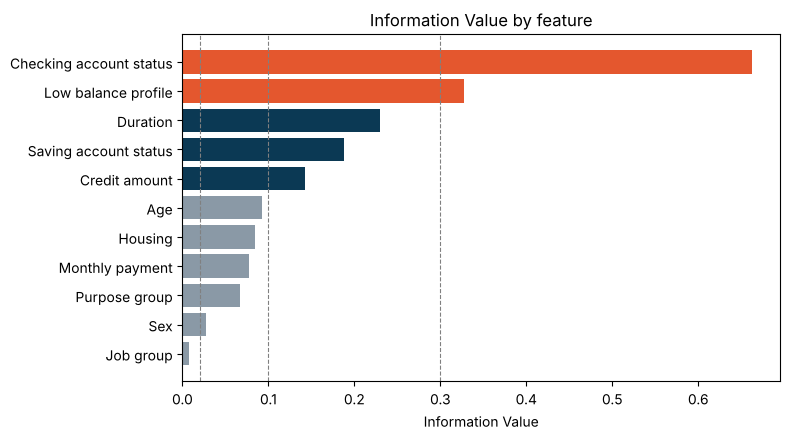

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ['#E4572E' if v >= 0.3 else '#0B3954' if v >= 0.1 else '#8A99A6' for v in iv_summary['IV']]
ax.barh(iv_summary['Description'][::-1], iv_summary['IV'][::-1], color=colors[::-1])
for x in [0.02, 0.1, 0.3]:
    ax.axvline(x, color='grey', linestyle='--', linewidth=0.8)
ax.set_xlabel('Information Value')
ax.set_title('Information Value by feature')
plt.tight_layout()
plt.show()

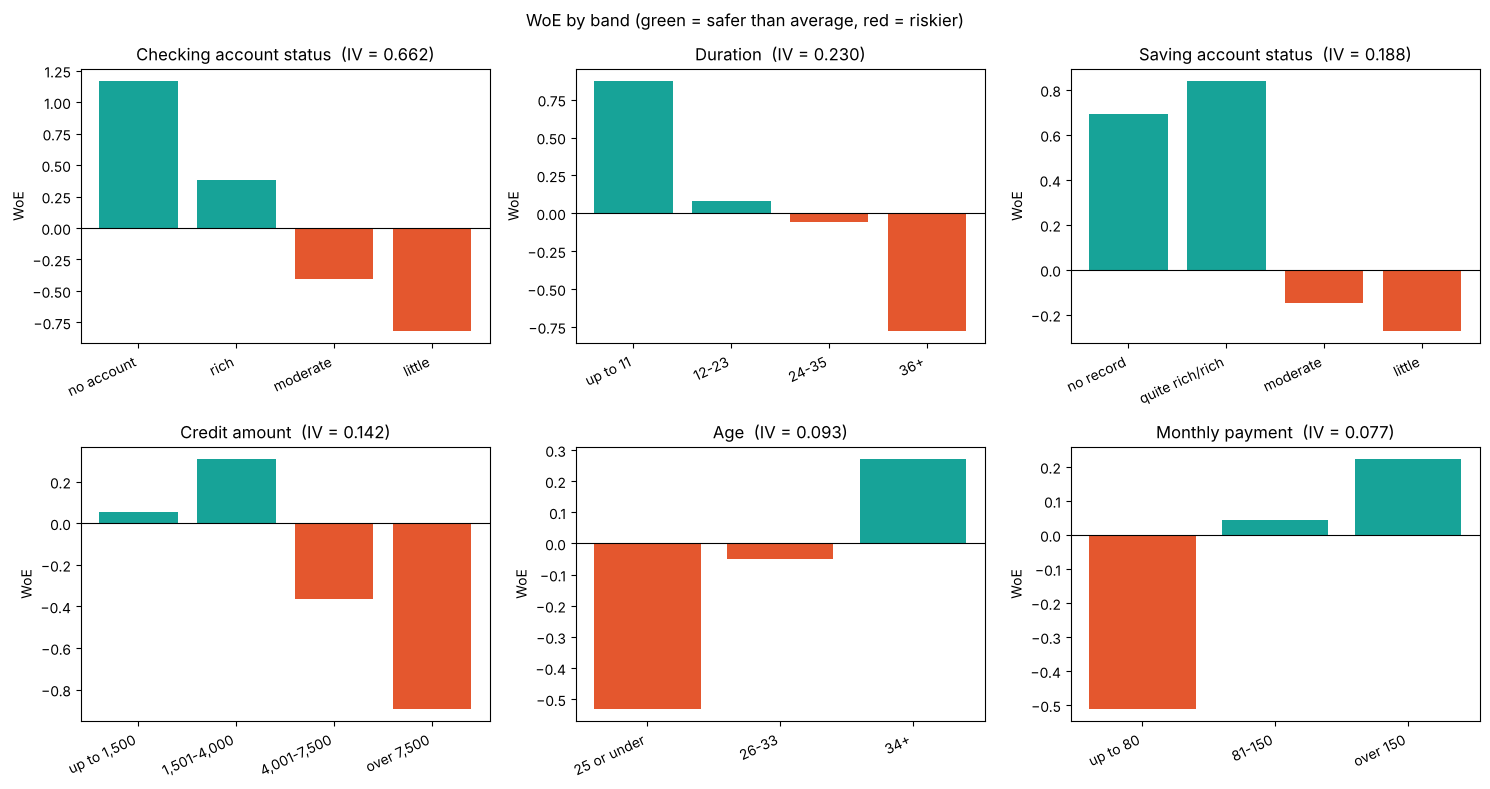

In [10]:
plot_features = ['checking_status', 'duration_bin', 'saving_status', 'credit_bin', 'age_bin', 'payment_bin']
order = {
    'checking_status': ['no account', 'rich', 'moderate', 'little'],
    'duration_bin': ['up to 11', '12-23', '24-35', '36+'],
    'saving_status': ['no record', 'quite rich/rich', 'moderate', 'little'],
    'credit_bin': ['up to 1,500', '1,501-4,000', '4,001-7,500', 'over 7,500'],
    'age_bin': ['25 or under', '26-33', '34+'],
    'payment_bin': ['up to 80', '81-150', 'over 150'],
}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.flatten(), plot_features):
    t = woe_tables[f].loc[order[f]]
    ax.bar(t.index, t['WoE'], color=['#17A398' if w > 0 else '#E4572E' for w in t['WoE']])
    ax.axhline(0, color='black', linewidth=0.8)
    iv_value = iv_summary.set_index('Feature').loc[f, 'IV']
    ax.set_title(f'{candidates[f]}  (IV = {iv_value:.3f})')
    ax.set_ylabel('WoE')
    plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
plt.suptitle('WoE by band (green = safer than average, red = riskier)')
plt.tight_layout()
plt.show()

## 4. WoE transformation

Each customer's band is replaced by the WoE of that band, so every feature becomes one number on the same scale.

In [11]:
woe_maps = {f: woe_tables[f]['WoE'].to_dict() for f in candidates}

woe_df = pd.DataFrame(index=fe.index)
for f in candidates:
    woe_df['woe_' + f] = fe[f].map(woe_maps[f])
woe_df['bad'] = fe['bad']

print('Missing values after transformation:', woe_df.isna().sum().sum())
woe_df.head()

Missing values after transformation: 0


,woe_checking_status,woe_low_balance_profile,woe_duration_bin,woe_saving_status,woe_credit_bin,woe_age_bin,woe_housing,woe_payment_bin,woe_purpose_group,woe_sex,woe_job_group,bad
0,-0.818,-0.912,0.872,0.692,0.056,0.271,0.192,0.223,0.404,0.111,0.021,0
1,-0.403,0.366,-0.777,-0.272,-0.366,-0.531,0.192,0.044,0.404,-0.237,0.021,1
2,1.167,0.366,0.078,-0.272,0.309,0.271,0.192,0.223,-0.367,0.111,0.074,0
3,-0.818,-0.912,-0.777,-0.272,-0.893,0.271,-0.476,0.223,-0.100,0.111,0.021,0
4,-0.818,-0.912,-0.058,-0.272,-0.366,0.271,-0.476,0.223,-0.071,0.111,0.021,1


## 5. Feature selection

Three rules decide which features go forward to modelling:
1. **IV of at least 0.02** (otherwise the feature has no useful signal).
2. **No protected characteristics** (`Sex` is excluded).
3. **No near-duplicates:** if two WoE features are correlated above 0.6, only the one with the higher IV is kept.

In [12]:
woe_cols = ['woe_' + f for f in iv_summary['Feature']]
corr = woe_df[woe_cols].corr().round(2)
corr.index = corr.columns = [c.replace('woe_', '') for c in corr.columns]
corr

,checking_status,low_balance_profile,duration_bin,saving_status,credit_bin,age_bin,housing,payment_bin,purpose_group,sex,job_group
checking_status,1.00,0.64,0.08,0.23,0.05,0.13,0.12,0.07,0.10,0.03,-0.00
low_balance_profile,0.64,1.00,0.07,0.25,0.00,0.06,0.14,0.06,0.09,0.02,-0.02
duration_bin,0.08,0.07,1.00,0.00,0.38,0.02,0.07,0.10,0.06,-0.07,0.16
saving_status,0.23,0.25,0.00,1.00,-0.03,0.10,0.01,0.02,0.01,0.03,0.03
credit_bin,0.05,0.00,0.38,-0.03,1.00,-0.03,0.09,-0.24,0.15,-0.05,0.26
age_bin,0.13,0.06,0.02,0.10,-0.03,1.00,0.09,0.06,-0.07,0.26,-0.15
housing,0.12,0.14,0.07,0.01,0.09,0.09,1.00,-0.07,0.12,0.11,0.09
payment_bin,0.07,0.06,0.10,0.02,-0.24,0.06,-0.07,1.00,-0.09,0.05,-0.17
purpose_group,0.10,0.09,0.06,0.01,0.15,-0.07,0.12,-0.09,1.00,0.01,0.07
sex,0.03,0.02,-0.07,0.03,-0.05,0.26,0.11,0.05,0.01,1.00,-0.06


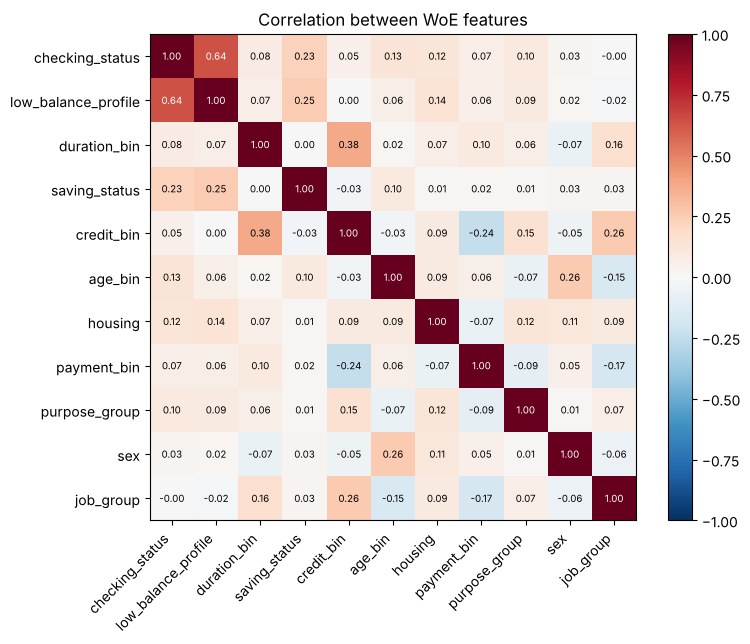

In [13]:
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr.values[i, j]) > 0.6 else 'black')
plt.colorbar(im)
ax.set_title('Correlation between WoE features')
plt.tight_layout()
plt.show()

In [14]:
selected, decisions = [], []
for _, row in iv_summary.iterrows():          # highest IV first
    f, iv = row['Feature'], row['IV']
    if iv < 0.02:
        decisions.append([f, iv, 'Dropped', 'IV below 0.02'])
        continue
    if f == 'sex':
        decisions.append([f, iv, 'Dropped', 'Protected characteristic'])
        continue
    clash = [s for s in selected if abs(corr.loc[f, s]) > 0.6]
    if clash:
        decisions.append([f, iv, 'Dropped', f'Correlated with {clash[0]} (r = {corr.loc[f, clash[0]]:.2f}), which has a higher IV'])
        continue
    selected.append(f)
    decisions.append([f, iv, 'Selected', 'Passes all rules'])

selection = pd.DataFrame(decisions, columns=['Feature', 'IV', 'Decision', 'Reason'])
print('Selected features:', selected)
selection

Selected features: ['checking_status', 'duration_bin', 'saving_status', 'credit_bin', 'age_bin', 'housing', 'payment_bin', 'purpose_group']


,Feature,IV,Decision,Reason
0,checking_status,0.662,Selected,Passes all rules
1,low_balance_profile,0.327,Dropped,"Correlated with checking_status (r = 0.64), which has a higher IV"
2,duration_bin,0.230,Selected,Passes all rules
3,saving_status,0.188,Selected,Passes all rules
4,credit_bin,0.142,Selected,Passes all rules
5,age_bin,0.093,Selected,Passes all rules
6,housing,0.084,Selected,Passes all rules
7,payment_bin,0.077,Selected,Passes all rules
8,purpose_group,0.067,Selected,Passes all rules
9,sex,0.027,Dropped,Protected characteristic


## 6. Does the WoE encoding work? Cross-validated test

A logistic regression is trained on the WoE features. To keep the test honest, the WoE values are
**recalculated inside each training fold** and then applied to the customers held out in that fold.
The result is compared with the previous notebook, which used the raw features (cross-validated ROC-AUC 0.744).
**Gini** = 2 x AUC - 1 is also shown because it is the usual measure in credit scoring.

In [15]:
def cross_validated_auc(features, n_splits=5, seed=42):
    folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    scores = []
    for train_idx, test_idx in folds.split(fe, fe['bad']):
        train, test = fe.iloc[train_idx], fe.iloc[test_idx]
        X_train, X_test = pd.DataFrame(index=train.index), pd.DataFrame(index=test.index)
        for f in features:
            mapping = woe_table(train, f)['WoE']                 # WoE learned on the training fold only
            X_train[f] = train[f].map(mapping)
            X_test[f] = test[f].map(mapping).fillna(0)
        model = LogisticRegression(max_iter=1000).fit(X_train, train['bad'])
        scores.append(roc_auc_score(test['bad'], model.predict_proba(X_test)[:, 1]))
    return np.mean(scores), np.std(scores)

all_non_protected = [f for f in iv_summary['Feature'] if f != 'sex']
results = []
for name, feats in [('All features except Sex', all_non_protected), ('Selected features', selected),
                    ('Top 3 features only', selected[:3])]:
    auc, sd = cross_validated_auc(feats)
    results.append([name, len(feats), round(auc, 3), round(sd, 3), round(2 * auc - 1, 3)])
results.append(['Raw features (notebook 04)', 9, 0.744, 0.021, round(2 * 0.744 - 1, 3)])
comparison = pd.DataFrame(results, columns=['Feature set', 'Features', 'ROC-AUC (5-fold)', 'Std', 'Gini'])
comparison

,Feature set,Features,ROC-AUC (5-fold),Std,Gini
0,All features except Sex,10,0.767,0.024,0.534
1,Selected features,8,0.767,0.026,0.533
2,Top 3 features only,3,0.743,0.031,0.487
3,Raw features (notebook 04),9,0.744,0.021,0.488


In [16]:
final_model = LogisticRegression(max_iter=1000).fit(woe_df[['woe_' + f for f in selected]], woe_df['bad'])
coefficients = pd.DataFrame({'Feature': selected, 'Coefficient': final_model.coef_[0].round(3)})
coefficients['Sign as expected'] = np.where(coefficients['Coefficient'] < 0, 'Yes', 'No')
coefficients

,Feature,Coefficient,Sign as expected
0,checking_status,-0.847,Yes
1,duration_bin,-0.625,Yes
2,saving_status,-0.710,Yes
3,credit_bin,-0.918,Yes
4,age_bin,-0.736,Yes
5,housing,-0.571,Yes
6,payment_bin,-1.171,Yes
7,purpose_group,-0.657,Yes


Every coefficient is **negative**, as it should be: a higher WoE means a safer band, so it lowers the chance of bad risk.
This confirms the WoE features work together sensibly and are ready for a scorecard model.

## 7. Save the model-ready datasets

In [17]:
os.makedirs('data/processed', exist_ok=True)

engineered_cols = ['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Credit amount', 'Duration', 'Purpose',
                   'checking_status', 'saving_status', 'has_checking_account', 'low_balance_profile', 'monthly_payment',
                   'log_credit_amount', 'long_loan', 'purpose_group', 'is_young', 'job_group', 'owns_home',
                   'duration_bin', 'age_bin', 'credit_bin', 'payment_bin', 'Risk', 'bad']
fe[engineered_cols].to_csv('data/processed/german_credit_engineered.csv', index=False)

woe_final = woe_df[['woe_' + f for f in selected] + ['bad']]
woe_final.to_csv('data/processed/german_credit_woe.csv', index=False)

woe_long = pd.concat([woe_tables[f].assign(Feature=f).rename_axis('Band').reset_index() for f in candidates])
woe_long = woe_long[['Feature', 'Band', 'Customers', 'Share (%)', 'Good', 'Bad', 'Bad rate (%)', 'WoE', 'IV part']]
woe_long.to_csv('data/processed/woe_iv_tables.csv', index=False)

for path in ['data/processed/german_credit_engineered.csv', 'data/processed/german_credit_woe.csv', 'data/processed/woe_iv_tables.csv']:
    print(path, pd.read_csv(path).shape)

data/processed/german_credit_engineered.csv (1000, 26)
data/processed/german_credit_woe.csv (1000, 9)
data/processed/woe_iv_tables.csv (37, 9)


## 8. Quick checks

In [18]:
checks = {
    'Dataset has 1,000 customers': len(fe) == 1000,
    'monthly_payment equals credit amount / duration': np.allclose(fe['monthly_payment'], fe['Credit amount'] / fe['Duration'], atol=0.01),
    'No missing values in engineered features': fe[new_features + list(bin_names.values())].isna().sum().sum() == 0,
    'Every band holds at least 5% of customers': all((t['Share (%)'] >= 5).all() for t in woe_tables.values()),
    'Every band has both good and bad customers': all(((t['Good'] > 0) & (t['Bad'] > 0)).all() for t in woe_tables.values()),
    'Each WoE table covers all 1,000 customers': all(t['Customers'].sum() == 1000 for t in woe_tables.values()),
    'All IV values are positive': (iv_summary['IV'] > 0).all(),
    'Duration WoE falls steadily as loans get longer': woe_tables['duration_bin'].loc[['up to 11', '12-23', '24-35', '36+'], 'WoE'].is_monotonic_decreasing,
    'WoE dataset has no missing values': woe_final.isna().sum().sum() == 0,
    'Sex is not among the selected features': 'sex' not in selected,
    'All model coefficients have the expected negative sign': (final_model.coef_[0] < 0).all(),
    'Selected features beat the raw-feature baseline (AUC 0.744)': comparison.loc[1, 'ROC-AUC (5-fold)'] > 0.744,
}
for name, passed in checks.items():
    print('PASS' if passed else 'FAIL', '-', name)
assert all(checks.values())
print()
print(f'All {len(checks)} checks passed')

PASS - Dataset has 1,000 customers
PASS - monthly_payment equals credit amount / duration
PASS - No missing values in engineered features
PASS - Every band holds at least 5% of customers
PASS - Every band has both good and bad customers
PASS - Each WoE table covers all 1,000 customers
PASS - All IV values are positive
PASS - Duration WoE falls steadily as loans get longer
PASS - WoE dataset has no missing values
PASS - Sex is not among the selected features
PASS - All model coefficients have the expected negative sign
PASS - Selected features beat the raw-feature baseline (AUC 0.744)

All 12 checks passed


## 9. Summary

- **11 new features** were engineered from the raw data, each based on a finding from the statistical analysis.
- All features were grouped into clear bands with at least 5% of customers each, and WoE and IV were calculated for every band and feature.
- **Checking account status** is by far the strongest feature (very strong IV), followed by the engineered **low balance profile**,
  **duration** and **saving account status** (medium IV).
- **Job group** was dropped (IV below 0.02), **Sex** was excluded as a protected characteristic, and near-duplicate features were removed.
- A logistic regression on the selected WoE features outperforms the raw-feature model from notebook 04,
  and all coefficients have the expected sign, so the features are ready for scorecard modelling.
- Three files were saved to `data/processed/`: the engineered dataset, the WoE-encoded dataset and the full WoE/IV tables.